In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gsw as gsw
import cartopy.crs as ccrs
import scipy
from cartopy.feature import LAND

# Steps
1. open dataset
2. Check the latitudes
3. Calculate the f,xscale,yscale, 
4. Interpolate through the date line along the longitudes
5. Differentiate in their respective directions and compute velocities
8. 

In [196]:
lats,lons= pd.read_csv('../data/latitude_EASE.csv').values,pd.read_csv('../data/longitude_EASE.csv').values
print(lats.shape,lons.shape)

grid=[]
no_structure=[]
for i in range(lats.shape[0]):
    griddy=[]
    for j in range(lats.shape[1]):
        coord=[lons[i,j],lats[i,j]]
        
        griddy.append(coord)
        no_structure.append(coord)
    grid.append(griddy)

no_structure=np.array(no_structure)
grid=np.array(grid)


(360, 361) (360, 361)


In [210]:
no_structure[:,0]

array([-134.84041, -135.     , -135.16049, ...,   44.67991,   44.8404 ,
         45.     ], shape=(129960,))

(360, 361)
1.8491111111111111
(12, 101, 1440)
(12, 101, 1440)


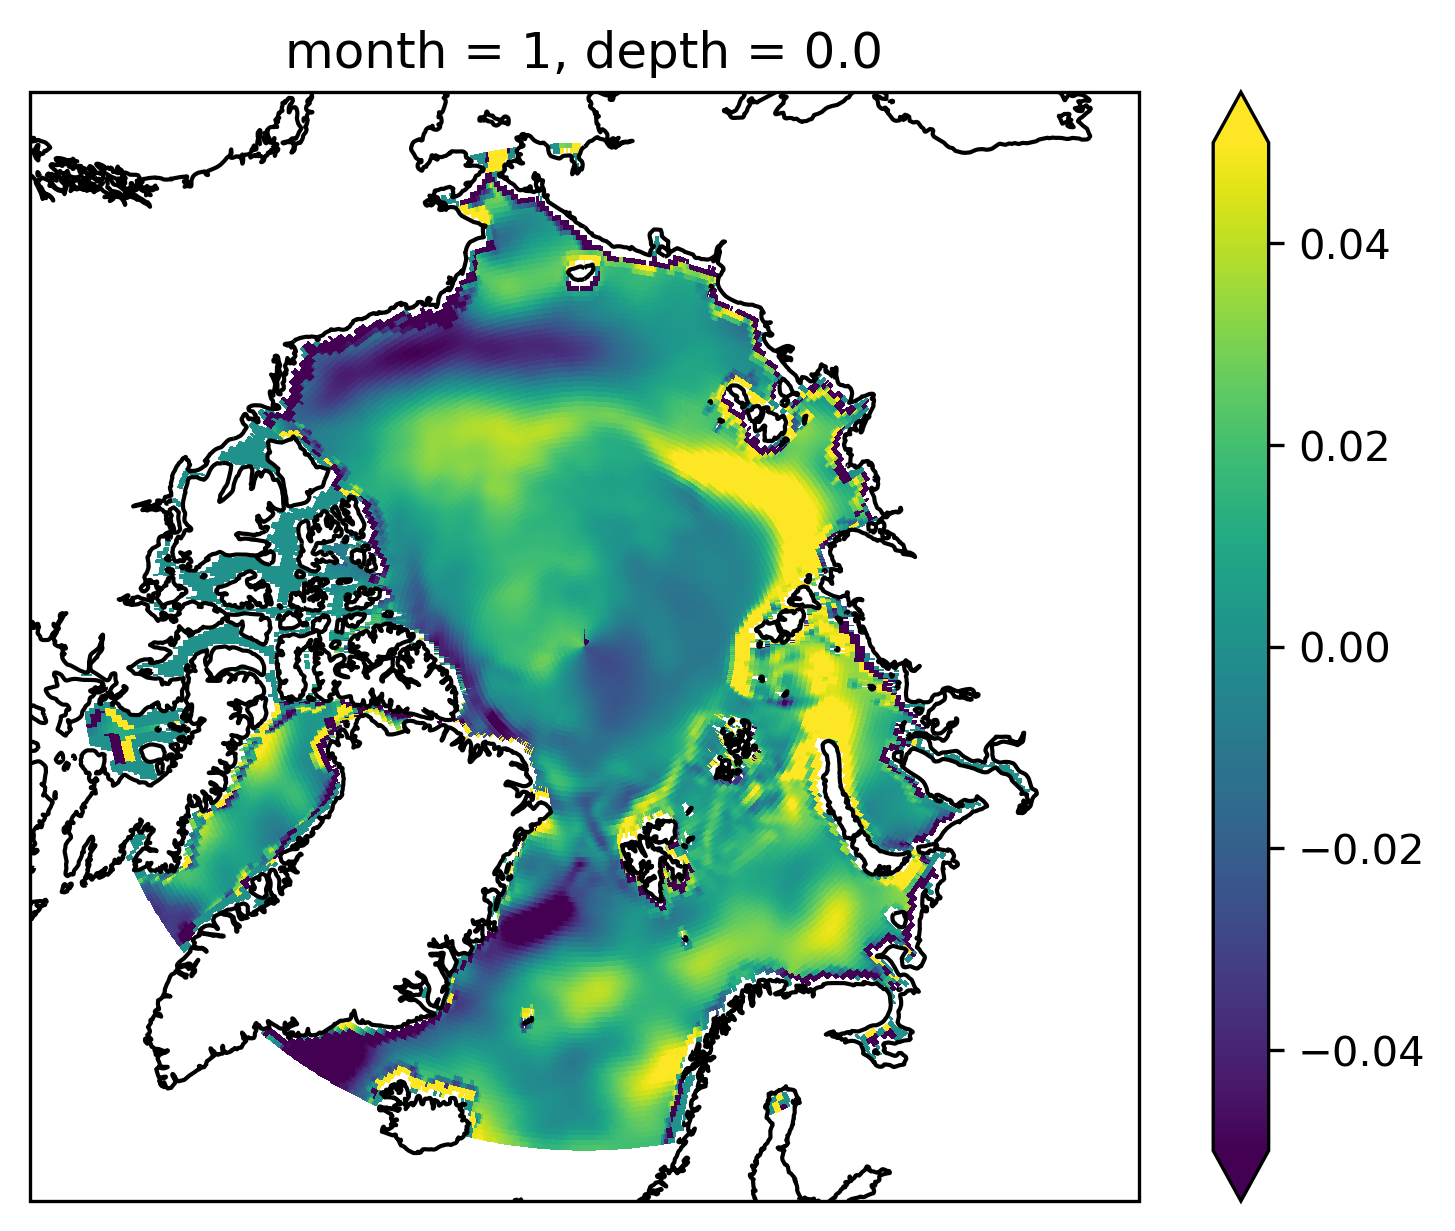

(12, 101, 1440)


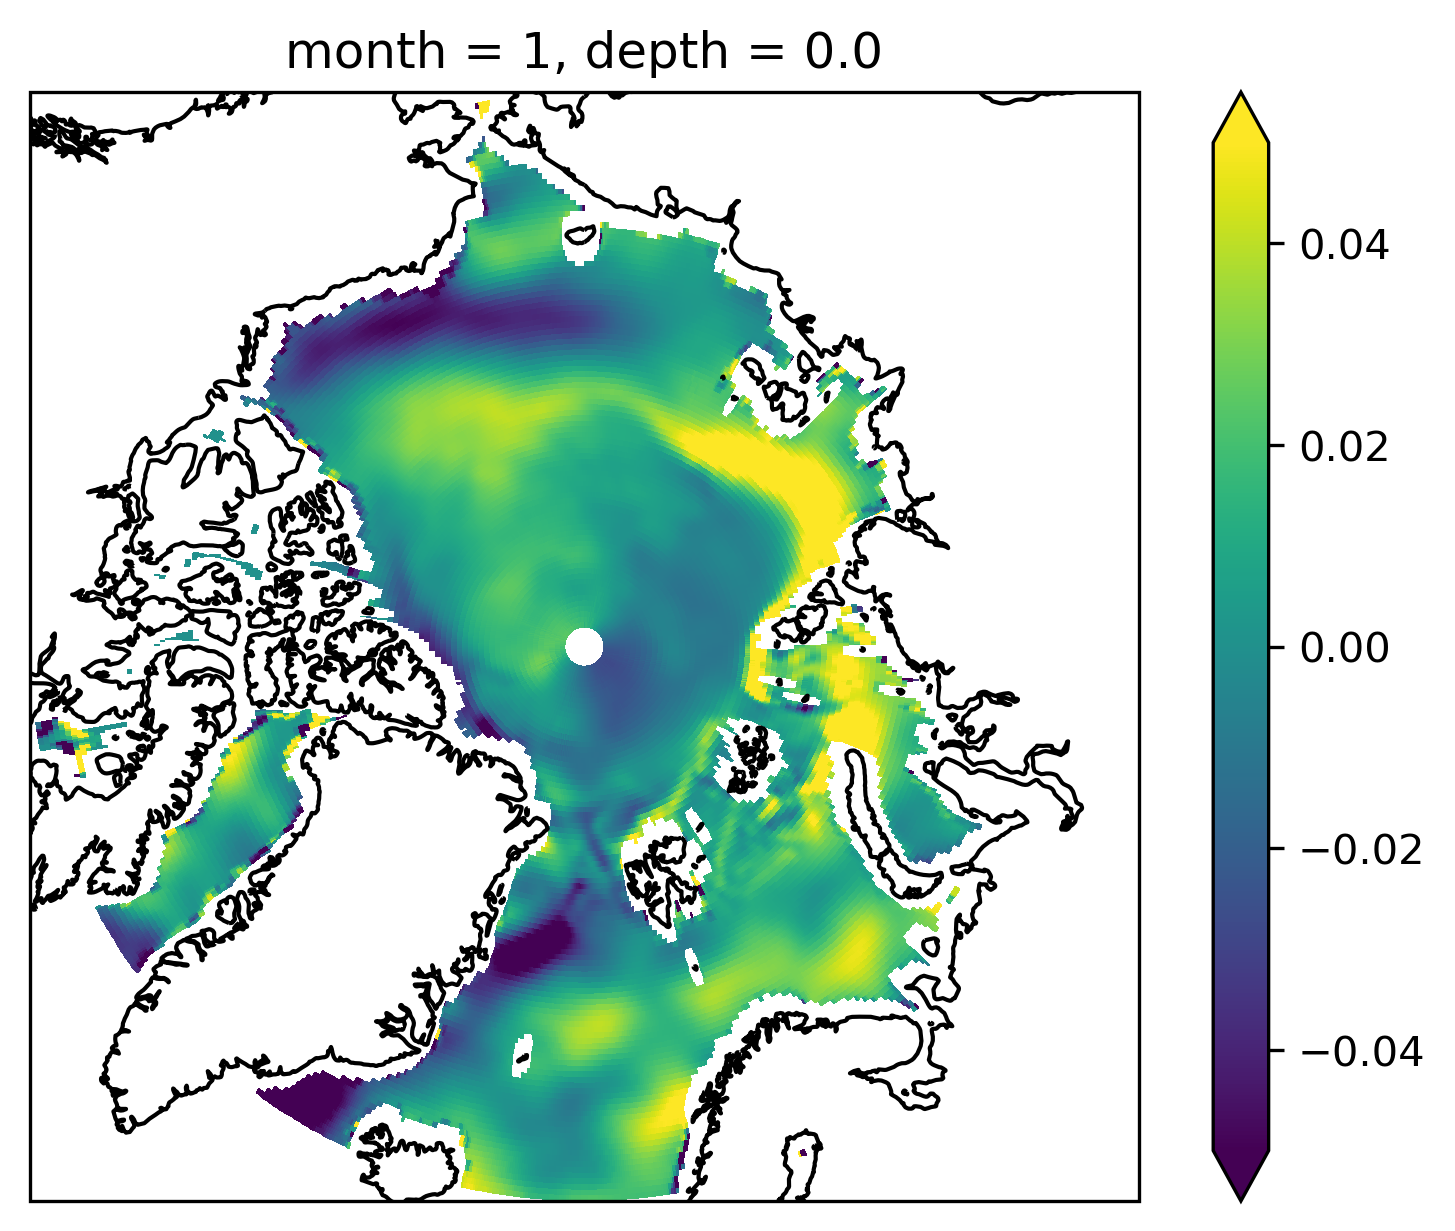

NameError: name 'no_structure' is not defined

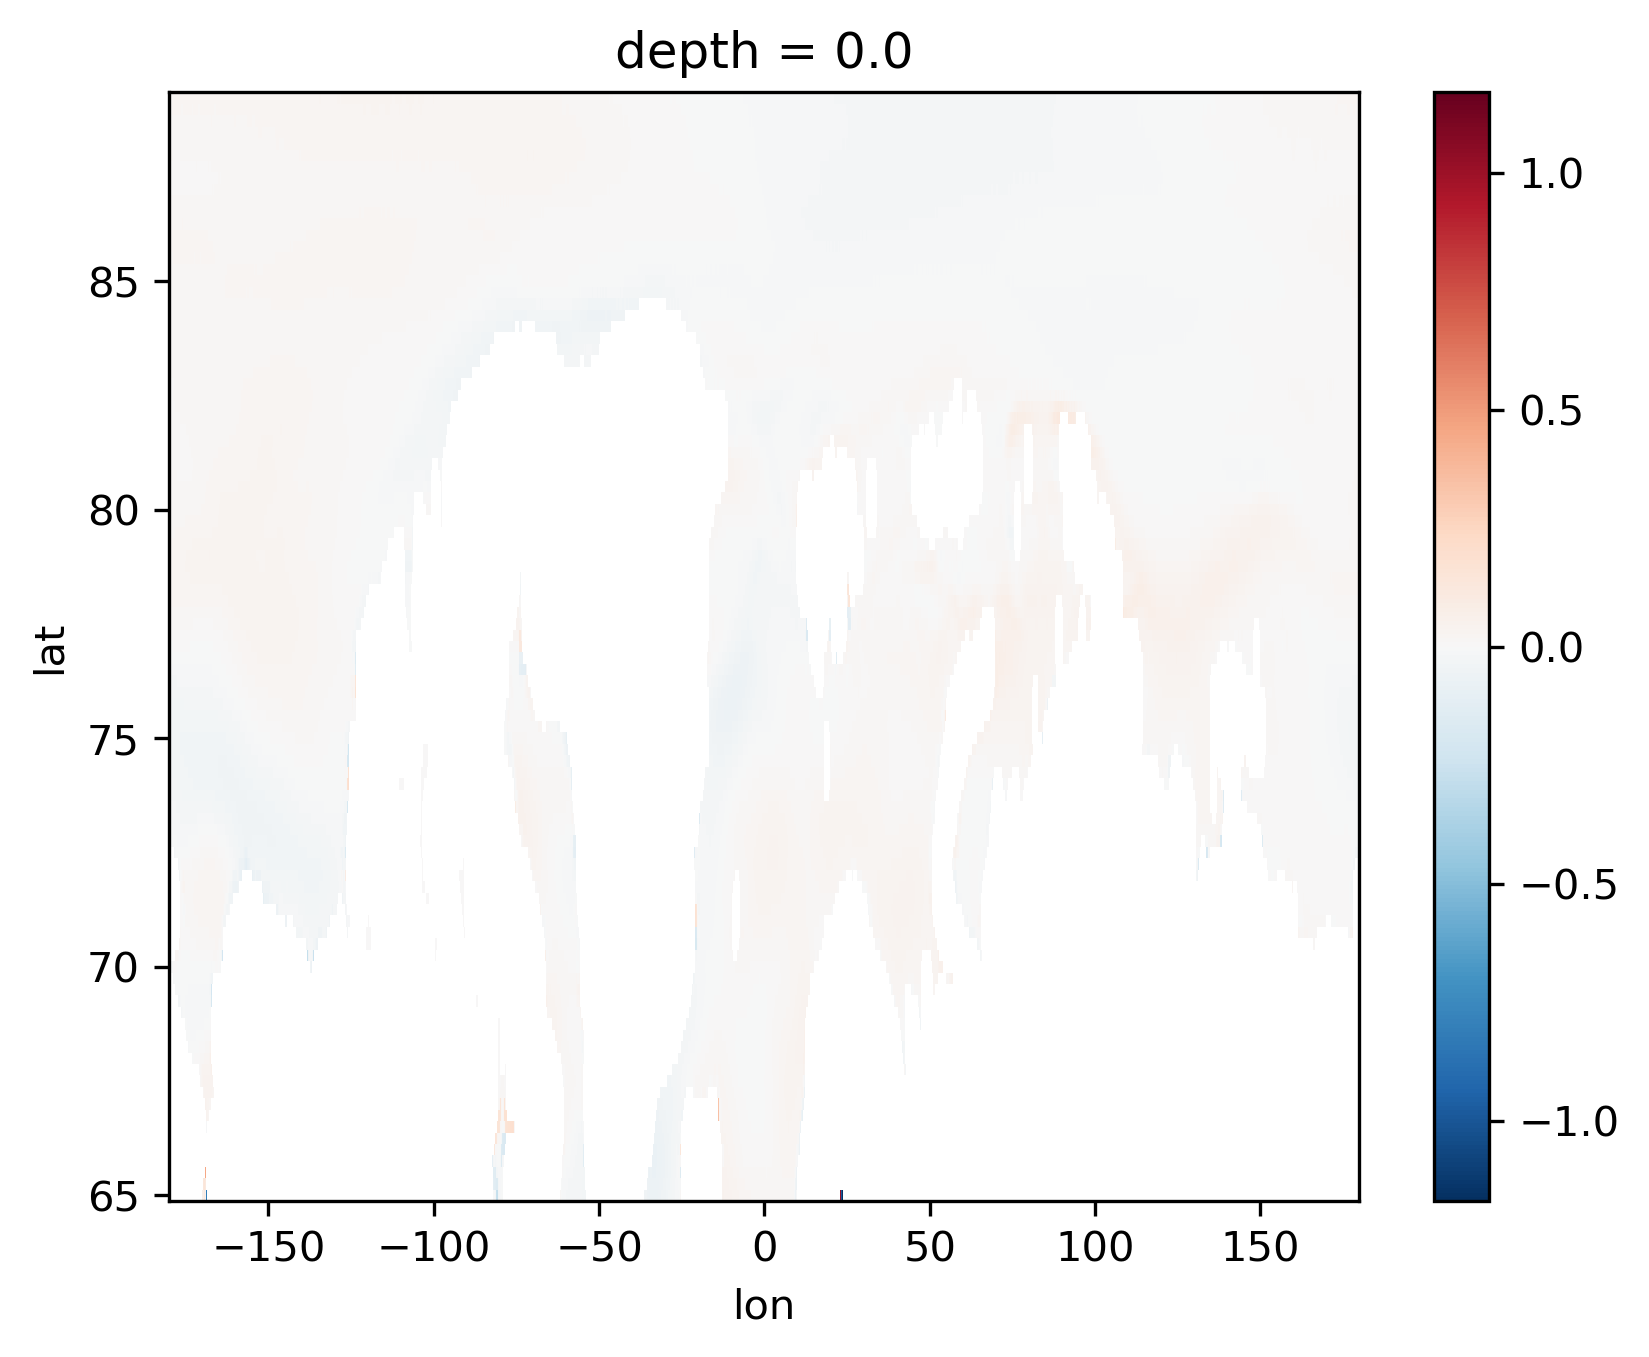

In [3]:
# 1. Open Dataset 
#    And readjust latitudes, and NaNs
ds = xr.open_dataset('../data/WOA_Bruno.nc')
ds.coords["lat"] = ds.coords["lat"].values[::-1] 
bath= pd.read_csv('../data/bathymetry_EASE.csv').values
avg_depth =(np.nanmean(bath))
print(bath.shape)
G=9.8
f= 2 * (2*np.pi/86400)*np.sin(ds["lat"]*(np.pi/180))
x_scale = 111000*np.cos(ds["lat"]*(np.pi/180))
y_scale=111000
L_d= np.round(np.sqrt(G*avg_depth)/np.mean(f.values))/y_scale
print(L_d/3)
T=ds['T'].isel({'depth':0,
                #'month':0
                }
                )
SSH=xr.where(np.isnan(T),0,ds['W-ssh'])
land=xr.where(np.isnan(T),1,0)

# Visual sanity check 
# fig,ax = plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()})
# SSH.isel({'month':10}).plot(cmap='coolwarm',transform=ccrs.PlateCarree())
# print(SSH.shape)
# ax.coastlines()

# 4. Fixing the Datetime line hole
# there is a whole around the dateline
# We identify the hole
bad_lon_idx = [-3,-2, -1, 0, 1,2]         # dateline gap
lat_min, lat_max = 65, 90

# Create a mask
bad_lons = ds.lon.isel(lon=bad_lon_idx)
badmask = ((ds.lat >= lat_min) & (ds.lat <= lat_max) & ds.lon.isin(bad_lons))
# badmask.plot(alpha=.5, transform=ccrs.PlateCarree())


# Replace the fake zeros in the mask with NaN
SSH2 = SSH.where(~badmask, np.nan)

# To take care of periodicity we need to roll the entire array and interpolate and then roll back
SSH2=SSH2.roll({'lon': 6})

# # Now linearly interpolate only along longitude
SSH_interp = SSH2.interpolate_na(#scipy.interpolate.interp1d(
    dim='lon',
    method="linear",
    fill_value="extrapolate",
    # period=True
)

# roll back
SSH_interp_rerolled=SSH_interp.roll({'lon':-6})

# Path the hole
SSH= xr.where(badmask,SSH_interp_rerolled,SSH)

# The values on land are still zeroes, we replace those by np.nan
SSH= xr.where(land,np.nan,SSH)

dx,dy=G*SSH.differentiate('lon')/x_scale, G*SSH.differentiate('lat')/y_scale
u= -dy/f
v= dx/f
speednan = np.isnan(u*v)
print(speednan.shape)
print(land.shape)
# ensure to remove the u/v values that are in zones where the opposite components is nan
# # i.e. some padded regions have values for u but not for v
u= xr.where(speednan, np.nan, u)
v= xr.where(speednan, np.nan, v)

#
fig,ax=plt.subplots(
    subplot_kw={'projection' : ccrs.NorthPolarStereo()},
    dpi=300)
# print(np.argmax(np.abs(u.flatten())))
# land.isel(month=1).plot(
#     # transform=ccrs.PlateCarree(),
#     alpha=.5)
u.isel(month=0).plot(
    transform=ccrs.PlateCarree(),
                     cmap='viridis',vmax=.05)
ax.coastlines()

plt.show()

# blurring
BLUR_RADIUS_CELLS=50*1e3/y_scale # After 5 standard deviation, a
print(u.shape)
u_blurred = scipy.ndimage.gaussian_filter(u, sigma=BLUR_RADIUS_CELLS, axes=(1,2)
                                          #, mode ='constant', cval=0
                                          )
u.values=u_blurred

v_blurred = scipy.ndimage.gaussian_filter(v, sigma=BLUR_RADIUS_CELLS, axes=(1,2)
                                          #, mode ='constant', cval=0
                                          )
v.values=v_blurred

# u.values=xr.where(land, 0, u)
# v.values=xr.where(land, 0, v)


# u = u.interpolate_na(#scipy.interpolate.interp1d(
#     dim='lat',
#     method="cubic",
#     fill_value="extrapolate",
#     # period=True
# )
u=u.sel(lat=slice(np.min(u.lat),89))
v=v.sel(lat=slice(np.min(v.lat),89))

fig,ax=plt.subplots(
    subplot_kw={'projection' : ccrs.NorthPolarStereo()},
    dpi=300)
# print(np.argmax(np.abs(u.flatten())))
# land.isel(month=1).plot(
#     # transform=ccrs.PlateCarree(),
#     alpha=.5)
u.isel(month=0).plot(
    transform=ccrs.PlateCarree(),
                     cmap='viridis',vmax=.05)
ax.coastlines()

plt.show()

fig,ax=plt.subplots(
    # subplot_kw={'projection' : ccrs.NorthPolarStereo()},
    dpi=300)


u_year=u.mean(dim='month')
v_year=v.mean(dim='month')
u_year.plot()

ax.plot(no_structure[0],no_structure[1])

In [ ]:
lats,lons= pd.read_csv('../data/latitude_EASE.csv').values,pd.read_csv('../data/longitude_EASE.csv').values
print(lats.shape,lons.shape)

grid=[]
no_structure=[]
for i in range(lats.shape[0]):
    griddy=[]
    for j in range(lats.shape[1]):
        coord=[lons[i,j],lats[i,j]]
        
        griddy.append(coord)
        no_structure.append(coord)
    grid.append(griddy)

no_structure=np.array(no_structure)
grid=np.array(grid)

I need to 
1. find the closest grid point to the u,
2. groupby grid point and average
3. save?
# Notes on Computer File 

In 3D, the straight-line (chord) distance between two points on a sphere grows monotonically with the great-circle distance. Therefore the nearest point by chord is also the nearest point on the sphere, and the wrap-around and polar distortion disappear. np.column_stack just places x, y, z side by side, giving an array of shape (N, 3), where each row is one point.

In [ ]:
from scipy.spatial import KDTree
# I used claude and chatgpt for this part because I was unsure how to best handle the finding the closest grid point on a sphere

rad = np.pi / 180 # to turn to radian
# EASE grid points as unit vectors
la = lats.ravel() * rad # goes from (i=360,j=361) to (k) k= 361*i+j 
lo= lons.ravel() * rad

# here we create a tree 
tree = KDTree(np.column_stack([np.cos(la)*np.cos(lo), np.cos(la)*np.sin(lo), np.sin(la)]))

# your source points
LON, LAT = np.meshgrid(u.lon.values, u.lat.values)      # we create arrays containing the latitudes and longitudes of the data points,
                                                        # in shape (97,1440)
sla, slo = LAT.ravel() * rad, LON.ravel() * rad # same as above we turn the 2D arrays into 1D lists for the KD tree

dist, flat_idx = tree.query(np.column_stack([np.cos(sla)*np.cos(slo), np.cos(sla)*np.sin(slo), np.sin(sla)])) 


In [254]:
print(np.column_stack([np.cos(la)*np.cos(lo), np.cos(la)*np.sin(lo), np.sin(la)]).shape)
print(np.column_stack([np.cos(sla)*np.cos(slo), np.cos(sla)*np.sin(slo), np.sin(sla)]).shape)

(129960, 3)
(139680, 3)


In [237]:
us = u.transpose("lat", "lon", "month").stack(pt=("lat", "lon"))
us = us.assign_coords(gridpoint=("pt", flat_idx))
u_grid = us.groupby("gridpoint").mean().reindex(gridpoint=np.arange(lats.size))
u_grid = u_grid.values.reshape(*lats.shape, -1)          # (360, 361, 12), if gridpoint is the first dim after reindex

AttributeError: 'DataArrayCoordinates' object has no attribute 'plot'

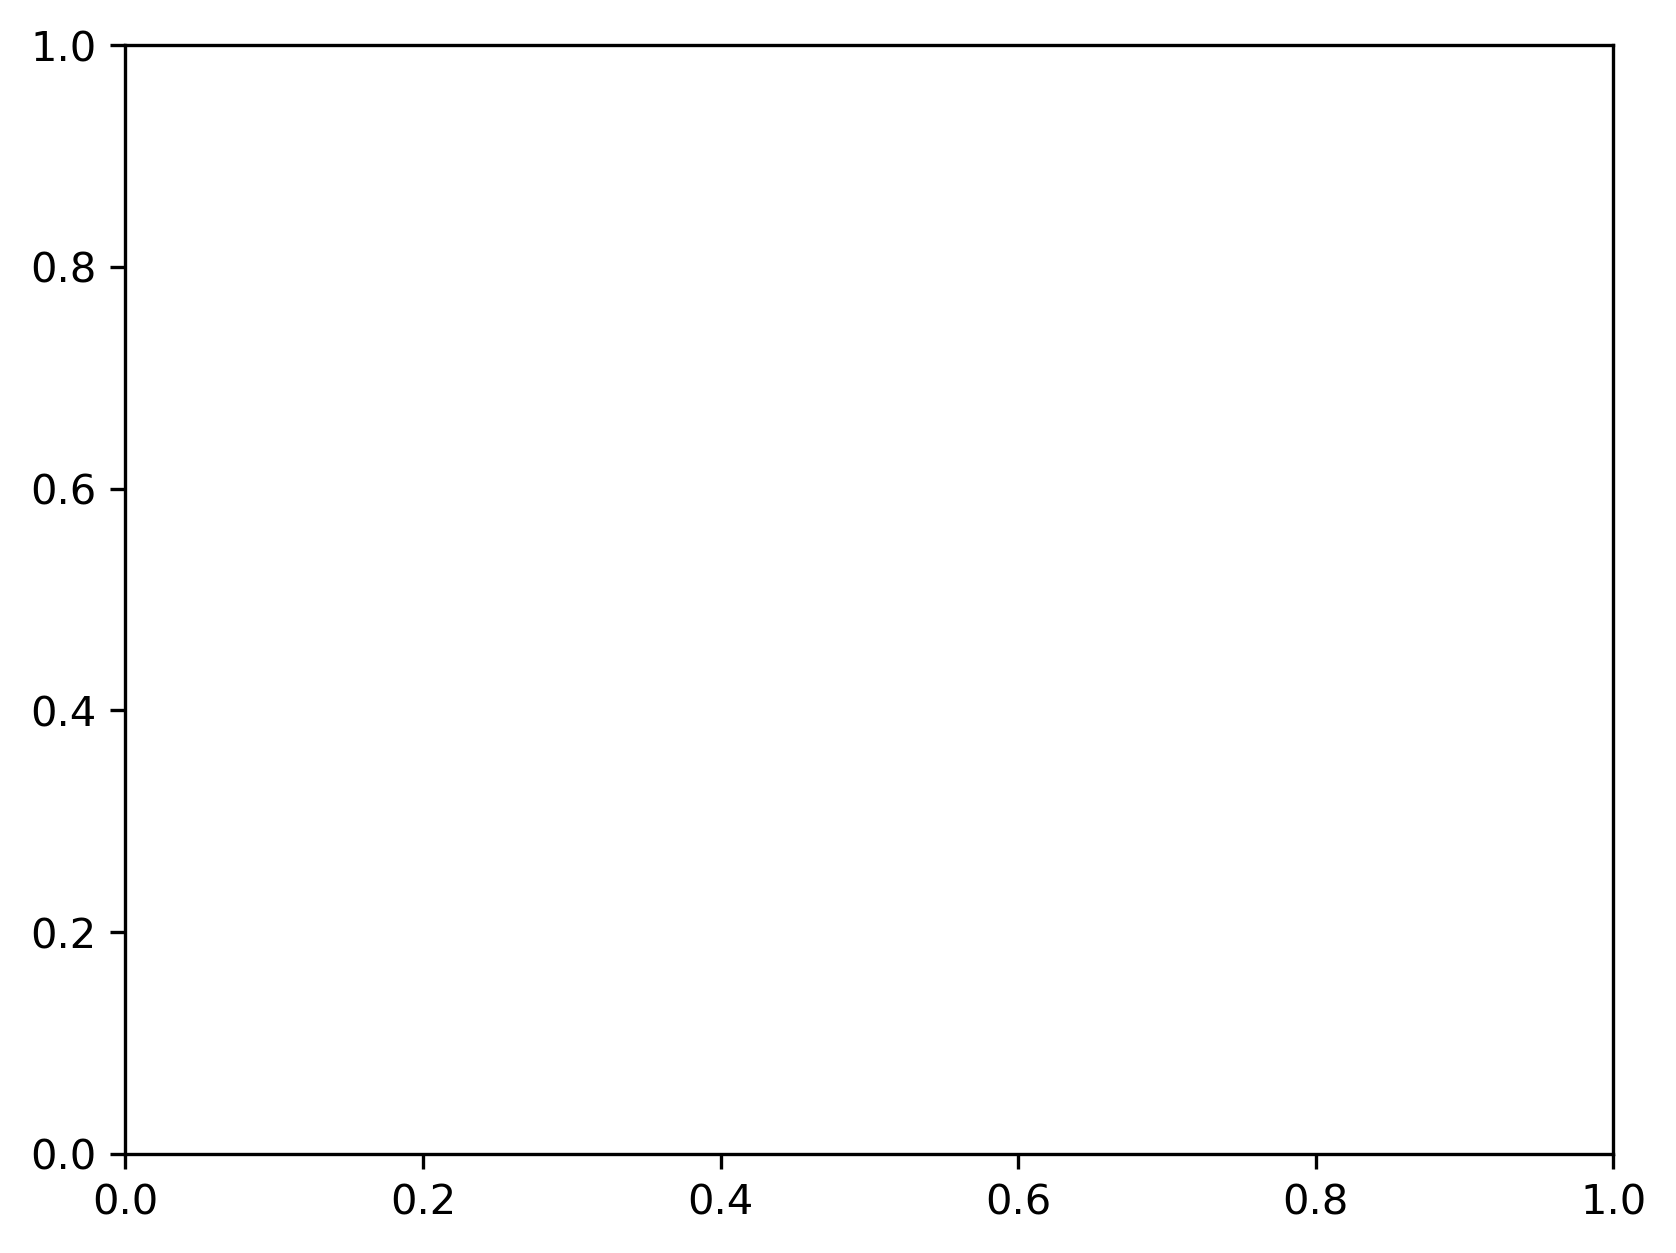

In [ ]:
fig,ax=plt.subplots(
    # subplot_kw={'projection' : ccrs.NorthPolarStereo()},
    dpi=300)


u_year=u.mean(dim='month')
v_year=v.mean(dim='month')
u_year.plot(ax=ax,alpha=1, 
            # transform=ccrs.PlateCarree()
            )

ax.scatter(no_structure[:,0],no_structure[:,1],s=.01, 
        #    transform=ccrs.PlateCarree(),
           alpha=.3)
# ax.coastlines()
# u_year.plot(ax=ax,alpha=1, transform=ccrs.PlateCarree())

In [171]:
lon=u.lon.values
print(lon)
dlat=np.roll(lon,1)-lon
print(dlat)

[-180.   -179.75 -179.5  ...  179.25  179.5   179.75]
[ 3.5975e+02 -2.5000e-01 -2.5000e-01 ... -2.5000e-01 -2.5000e-01
 -2.5000e-01]


In [ ]:
# we pad the SSH with the same values such that the gradients vanish at the coast 
# WOW No slip
# lim=10
# SSH_lon=SSH.interpolate_na(dim='lon',method='nearest',limit=lim)
# SSH_lat=SSH.interpolate_na(dim='lat',method='nearest',limit=lim)

# fig,ax=plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()},dpi=300)
# SSH_lon.isel(month=10).plot(transform=ccrs.PlateCarree(),cmap='viridis')
# land.plot(transform=ccrs.PlateCarree())

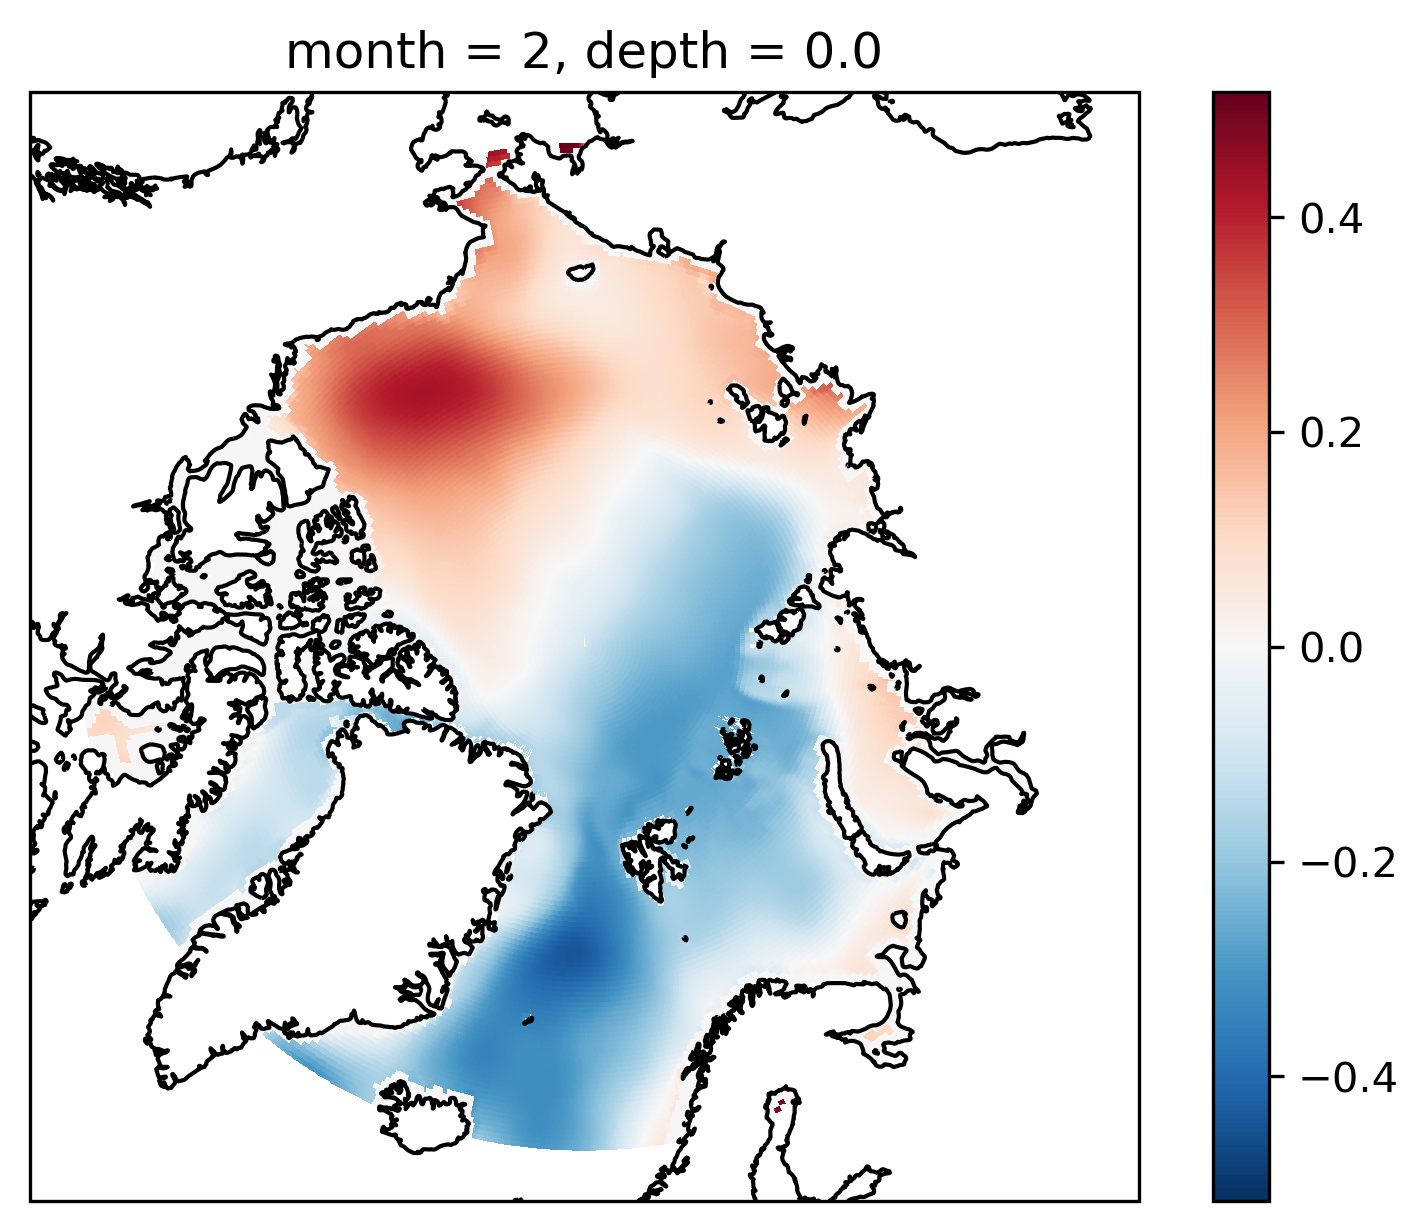

In [142]:
fig,ax = plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()}, dpi=300)
SSH.isel(month=1).plot(transform=ccrs.PlateCarree())
ax.coastlines()


In [114]:
# compute thee derivatives on the padded array for vanishing gradients
# dx = 9.8 * SSH_lon.differentiate("lon")/x_scale
# dy = 9.8 * SSH_lat.differentiate("lat")/y_scale
dx,dy=9.8*SSH.differentiate('lon')/x_scale, 9.8*SSH.differentiate('lat')/y_scale
u= -dy/f
v= dx/f
speednan = np.isnan(u*v)
print(speednan.shape)
print(land.shape)
# ensure to remove the u/v values that are in zones where the opposite components is nan
# # i.e. some padded regions have values for u but not for v
u= xr.where(speednan, np.nan, u)
v= xr.where(speednan, np.nan, v)

# # we now want to make the land 0 again such that we can interpolate between last non-zero and the coast where it is truly zero
# but the land mask is the same has shape 101,1440
# for i in range(len(ds.month)):
#     um= u.isel(month=i)
#     vm= v.isel(month=i)
#     u_intrp= xr.where(land,0,um)
#     v_intrp= xr.where(land,0,vm)

#     um = u_intrp.interpolate_na(
#         dim="lon",
#         method="cubic",
#         limit=50,
#         fill_value="extrapolate"
#     )
#     vm = v_intrp.interpolate_na(
#         dim="lat",
#         method="cubic",
#         limit=50,
#         fill_value="extrapolate"
#     )
#     um=xr.where(land,np.nan,um)
#     vm=xr.where(land, np.nan, vm)
#     u[{"month": i}] = um
#     v[{"month": i}] = vm

# speed=xr.where(land,0,np.sqrt(u**2+v**2))

(12, 101, 1440)
(12, 101, 1440)


In [ ]:
# u_intrp = xr.where(land, 0, u)
# v_intrp = xr.where(land, 0, v)

# lim=10
# u = u_intrp.interpolate_na(dim="lon", method="cubic", limit=lim, fill_value="extrapolate")
# v = v_intrp.interpolate_na(dim="lat", method="cubic", limit=lim, fill_value="extrapolate")

# u=u.where(~land,np.nan)

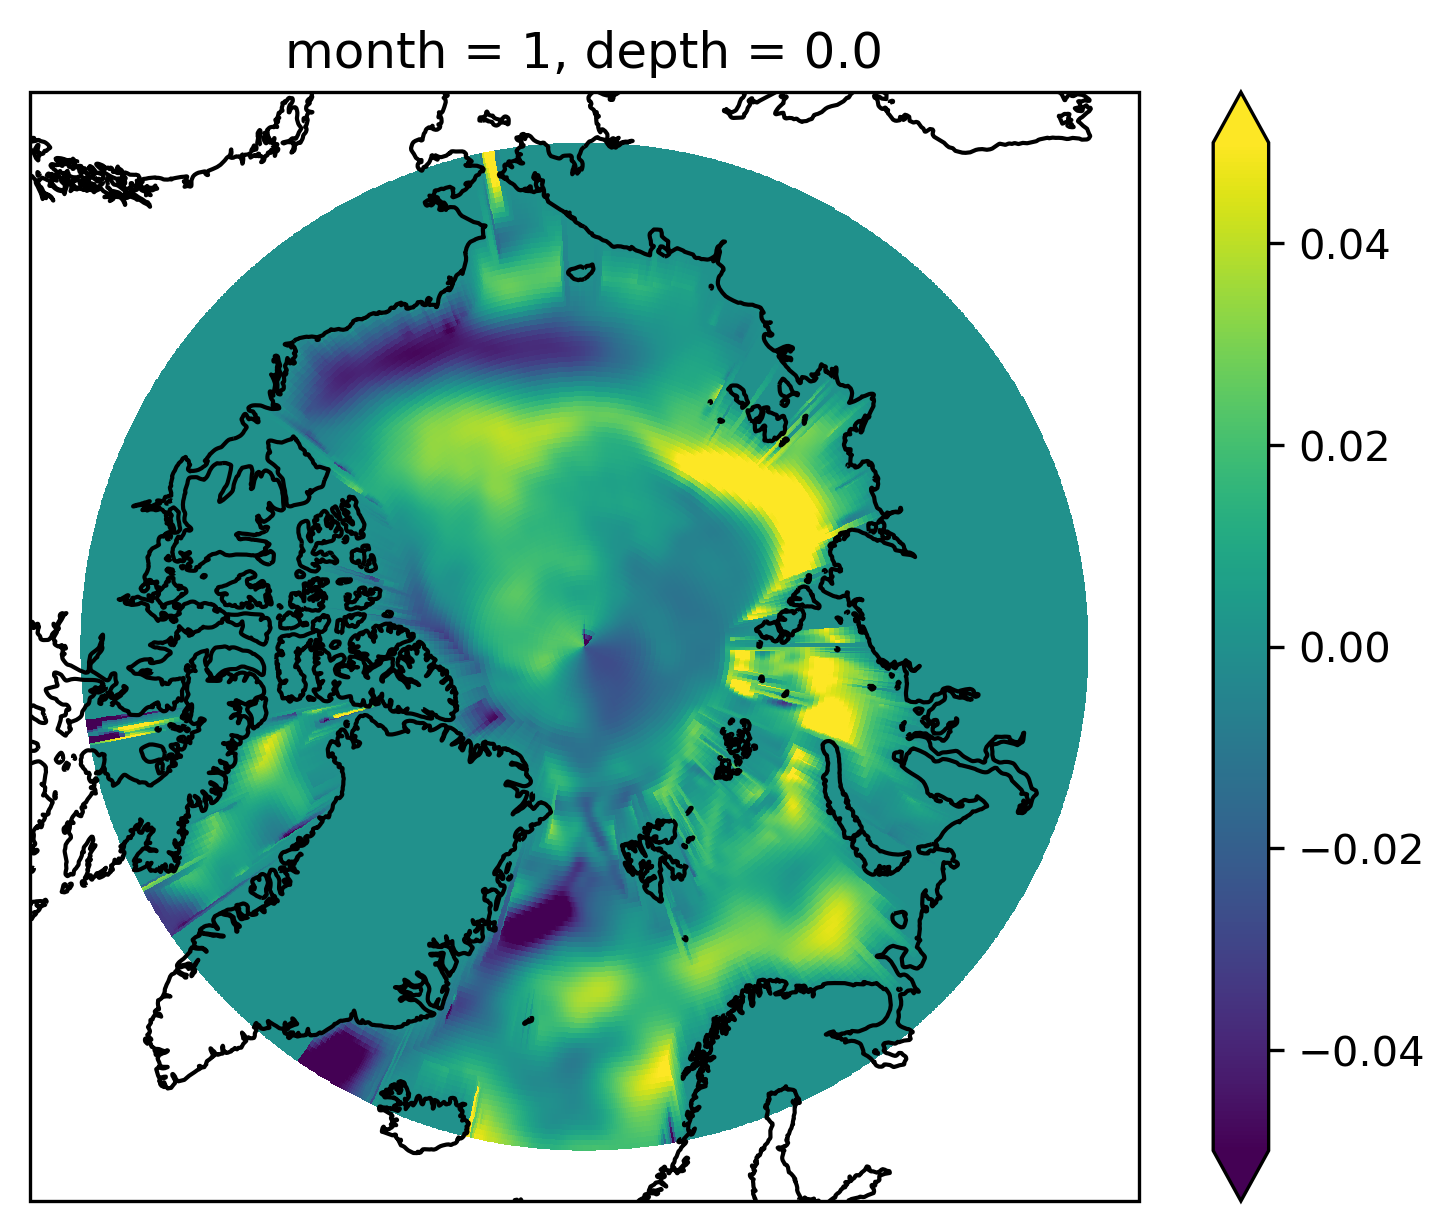

In [147]:
fig,ax=plt.subplots(
    subplot_kw={'projection' : ccrs.NorthPolarStereo()},
    dpi=300)
# print(np.argmax(np.abs(u.flatten())))
# land.isel(month=1).plot(
#     # transform=ccrs.PlateCarree(),
#     alpha=.5)
u.isel(month=0).plot(
    transform=ccrs.PlateCarree(),
                     cmap='viridis',vmax=.05)
ax.coastlines()

(12, 101, 1440)


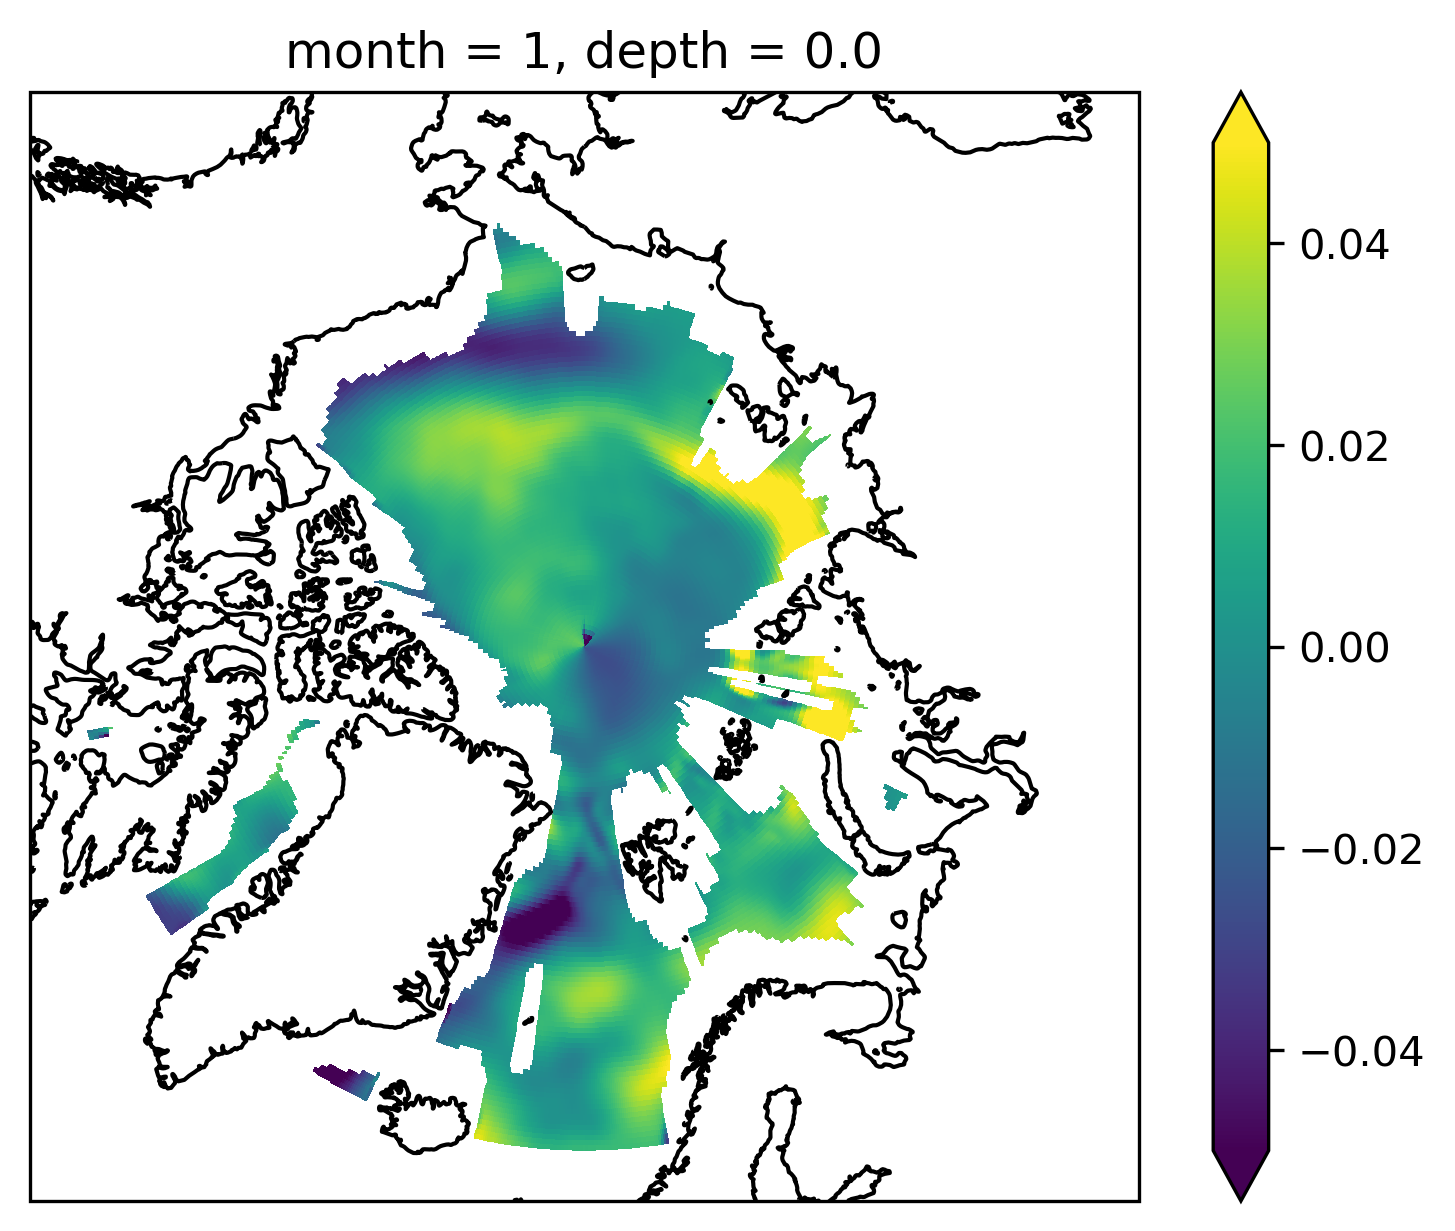

In [120]:
# blurring
BLUR_RADIUS_CELLS=.75
print(u.shape)
u_blurred = scipy.ndimage.gaussian_filter(u, sigma=BLUR_RADIUS_CELLS, axes=(1,2)
                                          #, mode ='constant', cval=0
                                          )
u.values=u_blurred

v_blurred = scipy.ndimage.gaussian_filter(v, sigma=BLUR_RADIUS_CELLS, axes=(1,2)
                                          #, mode ='constant', cval=0
                                          )
v.values=v_blurred

fig,ax=plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()},dpi=300)

# land.plot(transform=ccrs.PlateCarree(),alpha=.5)
u.isel(month=0).plot(transform=ccrs.PlateCarree(),cmap='viridis',vmax=.05)
ax.coastlines()


In [109]:
ds = xr.open_dataset('../data/WOA_Bruno.nc')
ds.coords["lat"] = ds.coords["lat"].values[::-1] 

f= 2 * (2*np.pi/86400)*np.sin(ds["lat"]*(np.pi/180))
x_scale = 111000*np.cos(ds["lat"]*(np.pi/180))
y_scale=111000


T=ds['T'].isel({'depth':0,
                'month':0})
SSH=xr.where(np.isnan(T),0,ds['W-ssh'])
land=xr.where(np.isnan(T),1,0)

# 4. Fixing the Datetime line hole
# there is a whole around the dateline
# We identify the hole
bad_lon_idx = [-3,-2, -1, 0, 1,2]         # dateline gap
lat_min, lat_max = 65, 90

# Create a mask
bad_lons = ds.lon.isel(lon=bad_lon_idx)
badmask = ((ds.lat >= lat_min) & (ds.lat <= lat_max) & ds.lon.isin(bad_lons))
# badmask.plot(alpha=.5, transform=ccrs.PlateCarree())


# Replace the fake zeros in the mask with NaN
SSH2 = SSH.where(~badmask, np.nan)

# To take care of periodicity we need to roll the entire array and interpolate and then roll back
SSH2=SSH2.roll({'lon': 6})

# # Now linearly interpolate only along longitude
SSH_interp = SSH2.interpolate_na(#scipy.interpolate.interp1d(
    dim='lon',
    method="linear",
    fill_value="extrapolate",
    # period=True
)

# roll back
SSH_interp_rerolled=SSH_interp.roll({'lon':-6})

# Path the hole
SSH= xr.where(badmask,SSH_interp_rerolled,SSH)

# The values on land are still zeroes, we replace those by np.nan
SSH= xr.where(SSH==0,np.nan,SSH)

# fig,ax = plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()}, dpi=300)
# SSH.isel(month=1).plot(transform=ccrs.PlateCarree())


# compute thee derivatives on the padded array for vanishing gradients
dx = 9.8 * SSH_lon.differentiate("lon")/x_scale
dy = 9.8 * SSH_lat.differentiate("lat")/y_scale
u= -dy/f
v= dx/f
speednan = np.isnan(u*v)
print(speednan.shape)
print(land.shape)
# ensure to remove the u/v values that are in zones where the opposite components is nan
# # i.e. some padded regions have values for u but not for v
u= xr.where(speednan, np.nan, u)
v= xr.where(speednan, np.nan, v)


(101, 1440, 12)
(101, 1440)


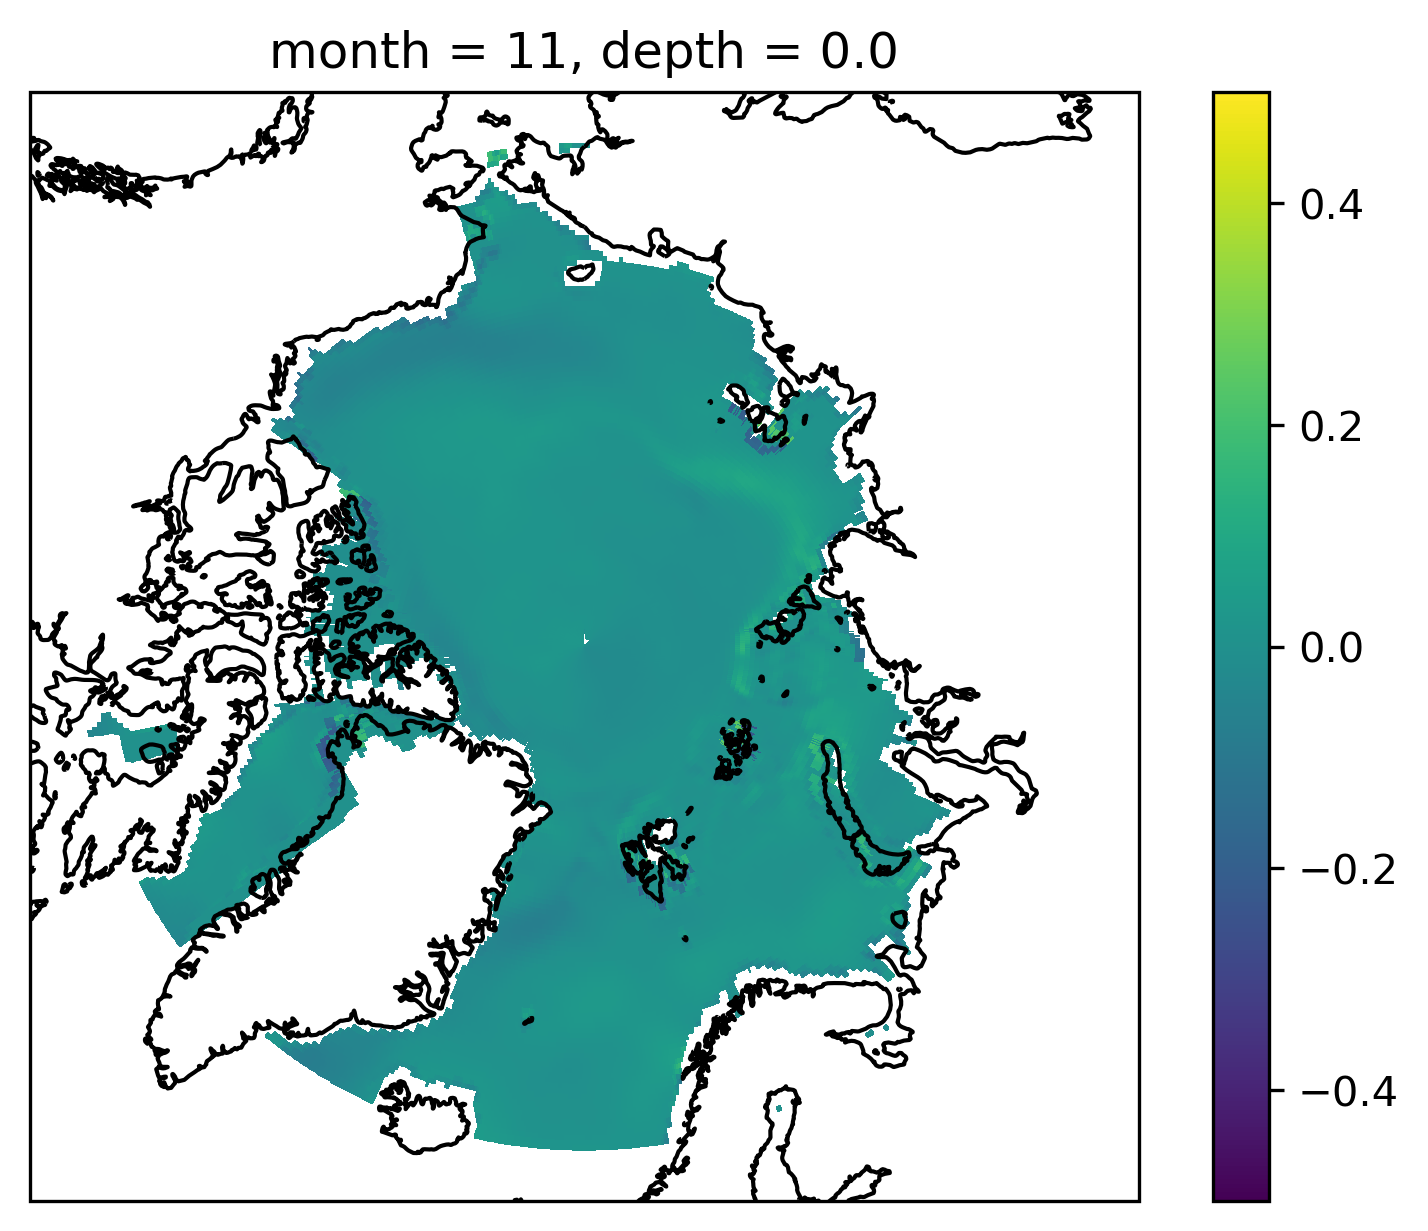

In [78]:
fig,ax=plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()},dpi=300)

# land.plot(transform=ccrs.PlateCarree(),alpha=.5)
u.isel(month=10).plot(transform=ccrs.PlateCarree(),cmap='viridis',vmax=.5)
ax.coastlines()

In [ ]:
# blurring
BLUR_RADIUS_CELLS=3
ds=ds.sel(lat=slice(65,89))
u,v =u.sel(lat=slice(65,89)),v.sel(lat=slice(65,89))
u_blurred = scipy.ndimage.gaussian_filter(u, sigma=BLUR_RADIUS_CELLS, axes=(1,1))
ds['u']=(['lat','lon'],u_blurred)

v_blurred = scipy.ndimage.gaussian_filter(v, sigma=BLUR_RADIUS_CELLS)
ds['v']=(['lat','lon'],v_blurred)

ds['speed']=(ds['u']**2+ds['v']**2)**.5

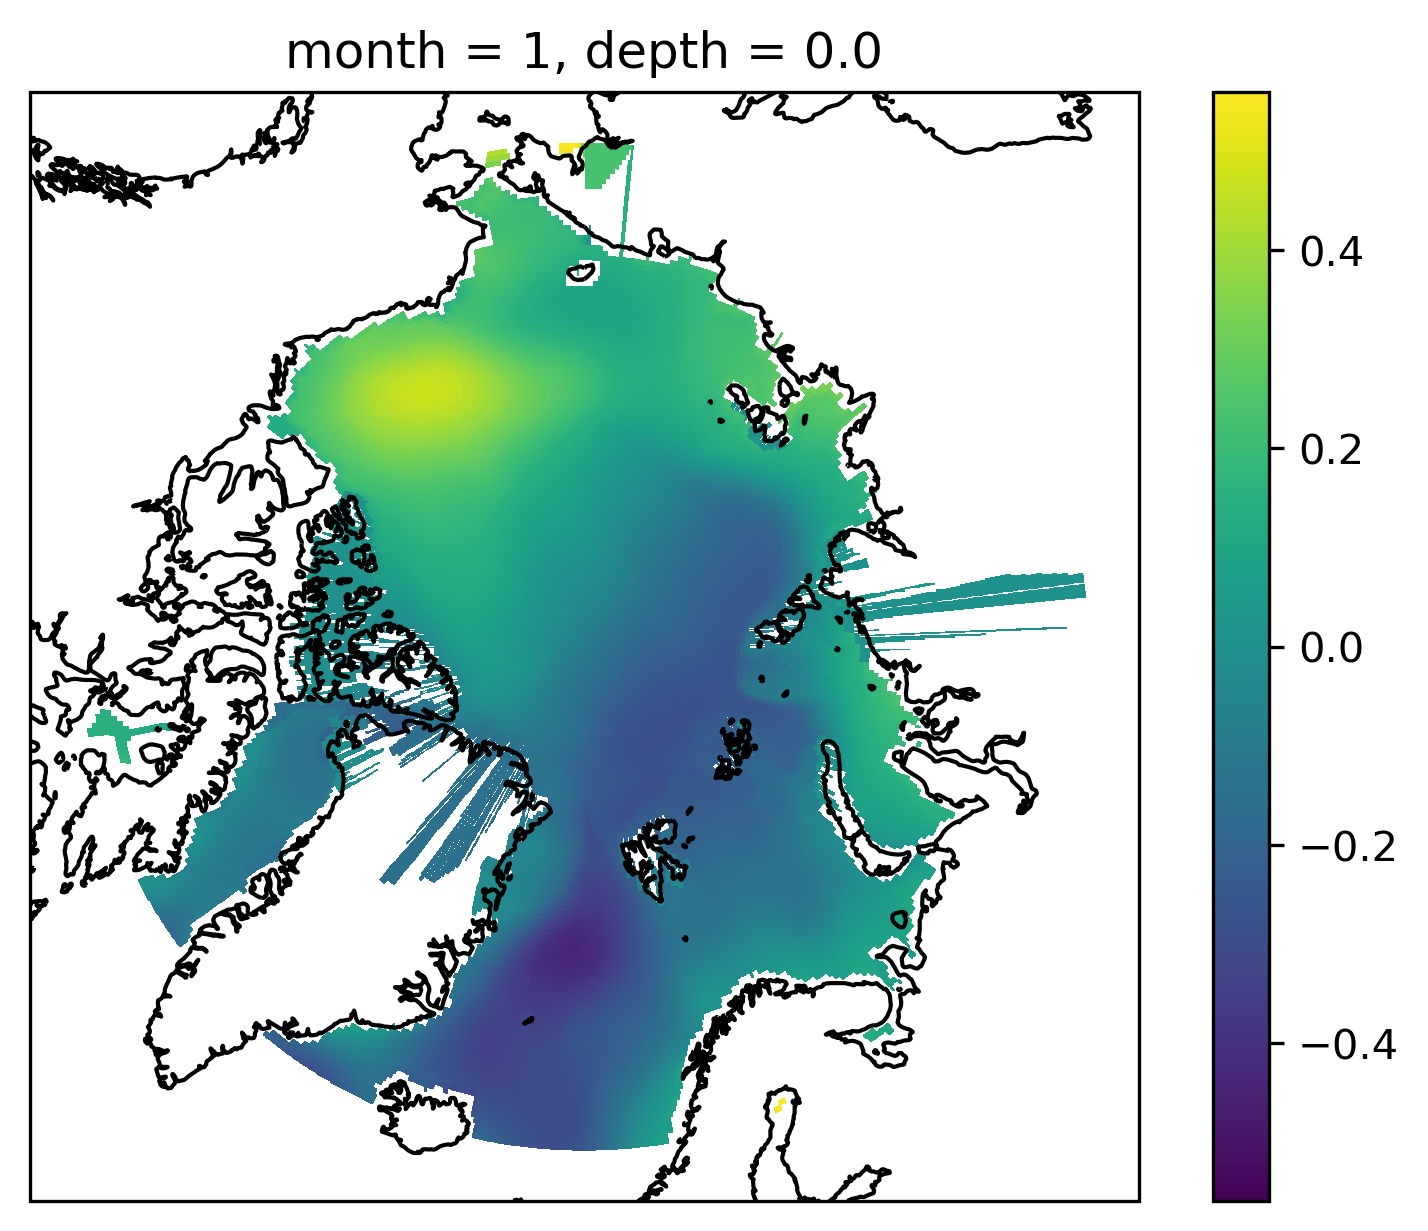

In [123]:

# # idx = scipy.ndimage.distance_transform_edt(land, return_indices=True, return_distances=False)
# # filled=  SSH.copy(data=SSH.values[idx[0], idx[1]])
# # fig,ax=plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()},dpi=300)

# #sHH=shh.interpolate_na(dim='lat',method='nearest',limit=20)
# # shh=xr.where(np.isnan(ds["Temp"].isel({"depth":0})), np.nan, shh)

# fig,ax=plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()},dpi=300)
# filled.isel(month=0).plot(transform=ccrs.PlateCarree(),cmap='viridis')
# ax.coastlines()